# 03 – Hypothesis Tests

**Goal:** Run the statistical tests defined in the README (H1–H6) to check whether the draws are consistent with a fair lottery.

**Input:** `data/processed/lotto_current_format.csv`

**Significance level:** α = 0.05, fixed in the README before running any test.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

ALPHA = 0.05  # fixed in the README before testing

df = pd.read_csv("../data/processed/lotto_current_format.csv", parse_dates=["date"])
num_cols = ["n1", "n2", "n3", "n4", "n5", "n6"]
n_draws = len(df)

print(n_draws)

1744


## H1 – Are the main numbers uniform?

- **H0:** every number from 1 to 37 has the same probability (6/37) of appearing in a draw.
- **H1:** at least one number has a different probability.
- **Method:** chi-square goodness-of-fit test. For each number it compares the observed count with the expected count, sums the squared differences (scaled by the expected count), and asks how likely such a large total would be if the lottery were fair.

In [2]:
observed = df[num_cols].stack().value_counts().sort_index()
expected = n_draws * 6 / 37

chi2, p_value = stats.chisquare(observed, f_exp=np.full(37, expected))

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {len(observed) - 1}")
print(f"p-value: {p_value:.3f}")
print("Reject H0" if p_value < ALPHA else "Fail to reject H0")

Chi-square statistic: 28.72
Degrees of freedom: 36
p-value: 0.800
Fail to reject H0


**Result**
- Chi-square statistic = 28.72 with 36 degrees of freedom, p-value = 0.80.
- Since p > 0.05, I fail to reject H0: there is no evidence that the main numbers are drawn with unequal probabilities.
- This does not prove that the lottery is fair. It only means that, with 1,744 draws, the observed differences are fully consistent with random variation.
- Caveat: the chi-square test treats the counts as if every drawn number were independent. In reality the six numbers of a draw are drawn without replacement, so the reference distribution is only approximate. The next step checks the result with a Monte Carlo simulation.

### H1 – Monte Carlo check
The classic chi-square test assumes that every drawn number is independent. In a real draw, the six numbers are drawn without replacement, which slightly reduces the random variation of the counts. To avoid relying on this approximation, I simulate a fair lottery many times (same number of draws, 6 numbers out of 37 without repetition), compute the chi-square statistic of each simulated lottery, and check where the observed value falls in this distribution.

In [4]:
rng = np.random.default_rng(42)  # fixed seed so the result is reproducible
n_sims = 10_000
sim_chi2 = np.empty(n_sims)

for i in range(n_sims):
    # give each of the 37 numbers a random score in every draw;
    # the 6 numbers with the lowest scores are the drawn ones
    drawn = rng.random((n_draws, 37)).argpartition(6, axis=1)[:, :6]
    counts = np.bincount(drawn.ravel(), minlength=37)
    sim_chi2[i] = ((counts - expected) ** 2 / expected).sum()

# +1 in both parts avoids reporting an impossible p-value of exactly 0
p_mc = (np.sum(sim_chi2 >= chi2) + 1) / (n_sims + 1)

print(f"Observed chi-square: {chi2:.2f}")
print(f"Mean of simulated chi-square: {sim_chi2.mean():.2f} (classic chi-square mean: 36)")
print(f"95th percentile of simulated chi-square: {np.percentile(sim_chi2, 95):.2f}")
print(f"Monte Carlo p-value: {p_mc:.3f}")

Observed chi-square: 28.72
Mean of simulated chi-square: 31.05 (classic chi-square mean: 36)
95th percentile of simulated chi-square: 43.83
Monte Carlo p-value: 0.601


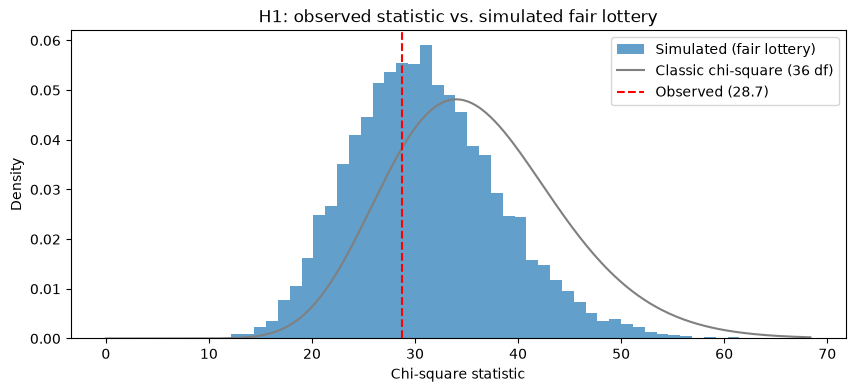

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(sim_chi2, bins=50, density=True, alpha=0.7, label="Simulated (fair lottery)")
x = np.linspace(0, sim_chi2.max(), 300)
ax.plot(x, stats.chi2.pdf(x, 36), color="gray", label="Classic chi-square (36 df)")
ax.axvline(chi2, color="red", linestyle="--", label=f"Observed ({chi2:.1f})")

ax.set_xlabel("Chi-square statistic")
ax.set_ylabel("Density")
ax.set_title("H1: observed statistic vs. simulated fair lottery")
ax.legend()

plt.show()

**Result**
- The simulated chi-square values average 31.05, not 36 as the classic distribution assumes. Drawing numbers without replacement reduces the variation in the counts, which is why the classic test is slightly conservative.
- The observed statistic (28.72) lies in the middle of the simulated distribution. The Monte Carlo p-value is 0.60, well above α = 0.05.
- **Conclusion for H1:** both the classic test (p = 0.80) and the simulation (p = 0.60) fail to reject H0. There is no evidence that the 37 main numbers are drawn with unequal probabilities.

## H2 – Is the strong number uniform?

- **H0:** every strong number from 1 to 7 has the same probability (1/7) in a draw.
- **H1:** at least one value has a different probability.
- **Method:** chi-square goodness-of-fit test. Unlike the main numbers, exactly one strong number is drawn per draw, so the counts follow the multinomial model that the classic test assumes, and no simulation is needed.

In [6]:
strong_observed = df["strong"].value_counts().sort_index()
strong_expected = n_draws / 7

chi2_strong, p_strong = stats.chisquare(strong_observed, f_exp=np.full(7, strong_expected))

print(f"Chi-square statistic: {chi2_strong:.2f}")
print(f"Degrees of freedom: {len(strong_observed) - 1}")
print(f"p-value: {p_strong:.3f}")
print("Reject H0" if p_strong < ALPHA else "Fail to reject H0")

Chi-square statistic: 2.97
Degrees of freedom: 6
p-value: 0.813
Fail to reject H0


**Result**
- Chi-square statistic = 2.97 with 6 degrees of freedom, p-value = 0.81.
- Since p > 0.05, I fail to reject H0: the observed strong number counts (236 to 264, expected 249) are fully consistent with a uniform draw.
- **Conclusion for H2:** no evidence that any strong number is favored or avoided.